# Solutions to the exercises of Chapter 17

Sample solutions for [Chapter 17, Simultaneous heat and mass transfer](../../notebooks/part4_mass_transfer/17_simultaneous_heat_mass.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import convective_mass, properties
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convective_mass, properties
from engtransport.constants import SIGMA_SB
from engtransport.numerics import bisect
from engtransport.plotting import panel_label, use_style

use_style()
cm = convective_mass
air = properties.dry_air_properties(300.0)
r_bl = (air["alpha"] / properties.water_vapour_diffusivity_air(300.0)) ** (2 / 3)
print(f"psychrometric ratio Le^(2/3) = {r_bl:.3f}")

psychrometric ratio Le^(2/3) = 0.907


## Exercise 1. Reading a psychrometer

Treating the wet bulb as the adiabatic saturation temperature, the humidity ratio is the
one whose $T_{as}$, Eq. (17.3), equals the reading; with the wick's psychrometric ratio, it
is the one whose wet-surface temperature, Eq. (17.4), does. Both are found by bisection in
the relative humidity.

In [2]:
T_dry, T_wet = 303.15, 293.15


def rh_from(reading):
    return bisect(lambda rh: reading(cm.humidity_ratio(T_dry, rh)) - T_wet, 1e-4, 1.0, xtol=1e-12)[0]


rh_as = rh_from(lambda W: cm.adiabatic_saturation_temperature(T_dry, W))
rh_bl = rh_from(lambda W: cm.wet_surface_temperature(T_dry, W, r_bl))
for label, rh in (("as T_as (Lewis)", rh_as), (f"with r = {r_bl:.3f}", rh_bl)):
    W = cm.humidity_ratio(T_dry, rh)
    print(f"{label:18s}: W = {1e3 * W:.2f} g/kg, RH = {100 * rh:.1f} %, dew point {properties.dew_point(T_dry, rh) - 273.15:.1f} C")

as T_as (Lewis)   : W = 10.48 g/kg, RH = 39.6 %, dew point 14.8 C
with r = 0.907    : W = 10.82 g/kg, RH = 40.9 %, dew point 15.3 C


Read as the adiabatic saturation temperature, the psychrometer gives 10.5 g/kg and 39.6 %
relative humidity; with the wick's ratio $r = 0.91$ the same reading means 10.8 g/kg and
40.9 %. The simple reading understates the humidity by 1.3 percentage points: a wick
with $r < 1$ evaporates relatively more than Lewis's relation allows, so it runs colder
than $T_{as}$, and a cold reading is taken for drier air. Meteorological psychrometer tables
use an empirical psychrometer constant for this reason.

## Exercise 2. A cooling coil that dehumidifies

The sensible flux is $h(T - T_s)$; the vapour flux follows from Eq. (17.4)'s mass part,
$\dot m'' = (h/(c_s r))\ln(1 + B)$, with $B < 0$ since the surface is drier than the air.
The latent heat released by condensation is $\dot m''h_{fg}$.

In [3]:
T, RH, T_s, h = 299.15, 0.60, 283.15, 50.0
W = cm.humidity_ratio(T, RH)
W_s = cm.humidity_ratio(T_s, 1.0)
c_s = cm.CP_DRY_AIR + W * cm.CP_VAPOUR
B = (W_s - W) / (1 + W)
m_cond = -h / (c_s * r_bl) * math.log1p(B)
q_sens = h * (T - T_s)
q_lat = m_cond * properties.saturated_water(T_s)["h_fg"]
print(f"W = {1e3 * W:.2f} g/kg, W_s = {1e3 * W_s:.2f} g/kg, B = {B:.4f}")
print(f"sensible {q_sens:.0f} W/m2, latent {q_lat:.0f} W/m2 (condensing {3600 * m_cond * 1e3:.0f} g/(m2 h)),"
      f" sensible heat ratio {q_sens / (q_sens + q_lat):.3f}")
print(f"with Lewis's r = 1: latent {q_lat * r_bl:.0f} W/m2, ratio {q_sens / (q_sens + q_lat * r_bl):.3f}")
print(f"condensation stops when the surface is above the dew point, {properties.dew_point(T, RH) - 273.15:.1f} C")

W = 12.61 g/kg, W_s = 7.62 g/kg, B = -0.0049
sensible 800 W/m2, latent 656 W/m2 (condensing 953 g/(m2 h)), sensible heat ratio 0.550
with Lewis's r = 1: latent 594 W/m2, ratio 0.574
condensation stops when the surface is above the dew point, 17.6 C


The fins remove 800 W/m² of sensible heat and 656 W/m² of latent heat, condensing
0.95 kg of water per square metre each hour; the sensible heat ratio is 0.55. Almost half
of what the coil removes is the latent heat of the water it takes out of the air; with
Lewis's $r = 1$ the latent part would be 9 % smaller. A surface above the air's dew point,
17.6 °C, would cool without drying the air at all. This is why the coil temperature is the
main lever on the humidity of a conditioned room: a colder coil dries more but must remove
more heat per unit of sensible cooling.

## Exercise 3. A canvas water bag

The canvas receives heat by convection and by radiation from surroundings at the air
temperature, $h(T - T_s) + h_r(T - T_s)$, with $h_r = \varepsilon\sigma(T^2 + T_s^2)(T + T_s)$,
and pays for evaporation at the rate of Eq. (17.4) with the convective $h$ alone.

In [4]:
T, RH, eps = 313.15, 0.10, 0.95
W = cm.humidity_ratio(T, RH)
c_s = cm.CP_DRY_AIR + W * cm.CP_VAPOUR


def canvas(h, radiation=True):
    def f(Ts):
        h_r = eps * SIGMA_SB * (T**2 + Ts**2) * (T + Ts) if radiation else 0.0
        Ws = cm.humidity_ratio(Ts, 1.0)
        evap = h / (c_s * r_bl) * math.log1p((Ws - W) / (1 + W)) * properties.saturated_water(Ts)["h_fg"]
        return (h + h_r) * (T - Ts) - evap
    return bisect(f, 274.0, T, xtol=1e-9)[0]


T_as = cm.adiabatic_saturation_temperature(T, W)
for h in (15.0, 30.0):
    Tc, Tw = canvas(h), canvas(h, radiation=False)
    print(f"h = {h:.0f}: canvas {Tc - 273.15:.2f} C, wet bulb without radiation {Tw - 273.15:.2f} C"
          f" (+{Tc - Tw:.2f} K); T_as {T_as - 273.15:.2f} C; air {T - 273.15:.0f} C")
h_grid = np.geomspace(2.0, 100.0, 40)
T_c = np.array([canvas(h) for h in h_grid])
T_w = np.array([canvas(h, radiation=False) for h in h_grid])

h = 15: canvas 20.35 C, wet bulb without radiation 17.97 C (+2.38 K); T_as 18.59 C; air 40 C
h = 30: canvas 19.24 C, wet bulb without radiation 17.97 C (+1.28 K); T_as 18.59 C; air 40 C


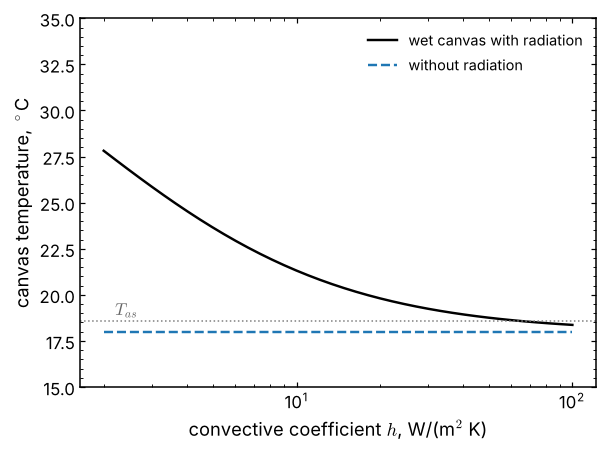

In [5]:
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.semilogx(h_grid, T_c - 273.15, "k-", label="wet canvas with radiation")
ax.semilogx(h_grid, T_w - 273.15, "C0--", label="without radiation")
ax.axhline(T_as - 273.15, color="0.5", ls=":", lw=1.0)
ax.text(2.2, T_as - 273.15 + 0.3, r"$T_{as}$", color="0.4")
ax.set_xlabel(r"convective coefficient $h$, W/(m$^2$ K)")
ax.set_ylabel(r"canvas temperature, $^\circ$C")
ax.set_ylim(15, 35)
ax.legend(loc="upper right")
plt.show()

**Figure S17.1.** Temperature of a wet canvas bag in air at 40 °C and 10 % humidity,
against the convective coefficient, with and without radiation from surroundings at the air
temperature.

In a light breeze ($h = 15$ W/(m² K)) the canvas settles at 20.4 °C, 2.4 K above the
18.0 °C it would reach without radiation, and almost 20 K below the air. Radiation from the
warm surroundings adds a coefficient $h_r \approx 6$ W/(m² K), two fifths of the
convective one, and it is a heat input that is not matched by extra evaporation. Doubling
$h$ brings the canvas to 19.2 °C, 1.3 K above the pure wet bulb. This is why a wet-bulb
thermometer must be shielded and ventilated: in still air it reads several kelvin high, and
why a water bag hung in the wind keeps water cooler than one in still air.

## Exercise 4. The water budget of a data centre

The design-day model of Section 17.4 is repeated for 2 MW. The pad's cooling is the heat
it takes out of the air, $\dot m_a c_s(T_{in} - T_{sup})$ while it runs, which a chiller
with $COP = 4$ would remove with a quarter of that in electricity.

In [6]:
NTU_pad, dT_servers, Q_it = 1.9, 12.0, 2.0e6
T_set, Td_max = 297.15, 288.15
c_s = cm.CP_DRY_AIR + 0.008 * cm.CP_VAPOUR
m_air = Q_it / (c_s * dT_servers)
hours = np.arange(0.0, 24.0, 0.25)
t_min, t_max, W = 22.0, 38.0, 0.0075
T_out_air = 273.15 + 0.5 * (t_min + t_max) - 0.5 * (t_max - t_min) * np.cos(2 * np.pi * (hours - 5) / 24)
W_lim = cm.humidity_ratio(Td_max, 1.0)
water, pad_cool, trim = (np.zeros(hours.size) for _ in range(3))
for i, t in enumerate(T_out_air):
    if t <= T_set:
        continue
    T_o, W_o, _ = cm.evaporative_pad(t, W, NTU_pad)
    f = min(1.0, (t - T_set) / (t - T_o), max(0.0, (W_lim - W) / (W_o - W)))
    T_sup = t - f * (t - T_o)
    water[i] = m_air * f * (W_o - W)
    pad_cool[i] = m_air * c_s * (t - T_sup)
    trim[i] = m_air * c_s * max(T_sup - T_set, 0.0)
dt = 0.25 * 3600
evap_day = np.sum(water) * dt
make_up = 1.5 * evap_day
E_it = Q_it * 24 * 3600 / 3.6e6                    # kWh of server energy per day
print(f"evaporated {evap_day / 1e3:.1f} t/day, with bleed {make_up / 1e3:.1f} t/day, {90 * make_up / 1e3:.0f} t per summer;"
      f" {make_up / E_it:.2f} L per kWh of servers")
cool_day = np.sum(pad_cool) * dt / 3.6e9           # MWh
trim_day = np.sum(trim) * dt / 3.6e9
print(f"pad cooling {cool_day:.1f} MWh_th/day, would need {cool_day / 4:.2f} MWh of chiller electricity;"
      f" chiller trim still needed {trim_day:.1f} MWh_th/day = {trim_day / 4:.2f} MWh electricity")
print(f"electricity saved per litre of make-up water: {cool_day / 4 * 1e3 / make_up:.3f} kWh/L")

evaporated 26.2 t/day, with bleed 39.3 t/day, 3536 t per summer; 0.82 L per kWh of servers
pad cooling 17.9 MWh_th/day, would need 4.47 MWh of chiller electricity; chiller trim still needed 7.3 MWh_th/day = 1.83 MWh electricity
electricity saved per litre of make-up water: 0.114 kWh/L


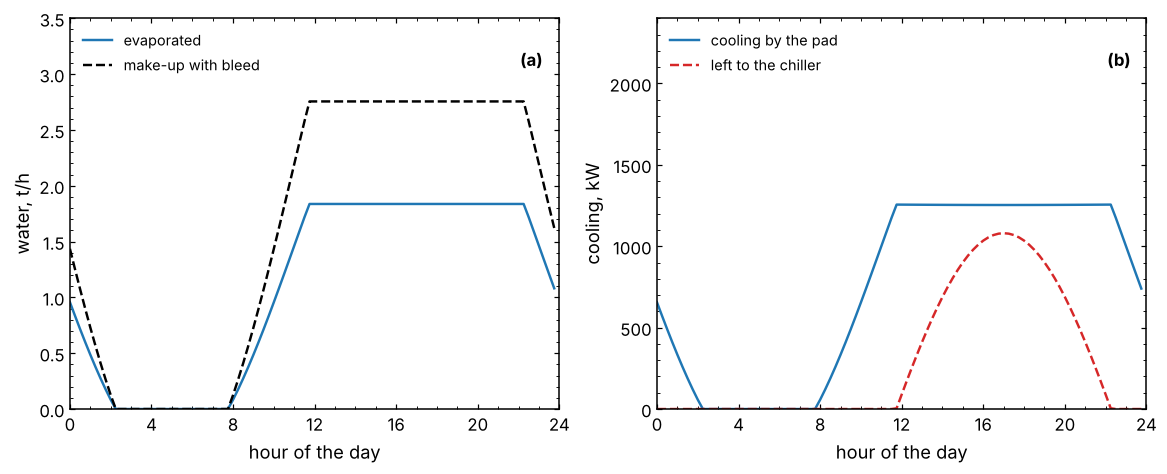

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax1.plot(hours, 3600 * water / 1e3, "C0-", label="evaporated")
ax1.plot(hours, 1.5 * 3600 * water / 1e3, "k--", label="make-up with bleed")
ax1.set_xlabel("hour of the day")
ax1.set_ylabel("water, t/h")
ax1.set_xlim(0, 24)
ax1.set_xticks(range(0, 25, 4))
ax1.set_ylim(0, 3.5)
ax1.legend(loc="upper left")
panel_label(ax1, "(a)", x=0.92, y=0.92)
ax2.plot(hours, pad_cool / 1e3, "C0-", label="cooling by the pad")
ax2.plot(hours, trim / 1e3, "C3--", label="left to the chiller")
ax2.set_xlabel("hour of the day")
ax2.set_ylabel("cooling, kW")
ax2.set_xlim(0, 24)
ax2.set_xticks(range(0, 25, 4))
ax2.set_ylim(0, 2400)
ax2.legend(loc="upper left")
panel_label(ax2, "(b)", x=0.92, y=0.92)
plt.show()

**Figure S17.2.** A 2 MW data hall in Shymkent on the design day, with a 15 °C dew-point
limit. (a) Water evaporated by the pads and the make-up water with three cycles of
concentration. (b) Cooling of the outdoor air done by the pads, and the part left to a
chiller.

The pads evaporate 26 t of water a day; with the bleed, the make-up is 39 t a day, or
3.5 thousand tonnes over a 90-day summer like the design day: 0.82 litres per kilowatt-hour
of server energy. In return they do 17.9 MWh of cooling a day, which a chiller would have
needed 4.5 MWh of electricity to provide; the chiller still trims 7.3 MWh of heat for
1.8 MWh. Each litre of make-up water thus saves about 0.11 kWh of electricity. Whether
that trade is worth making depends on the price and scarcity of water at the site, which
in southern Kazakhstan is a real constraint: the assumed bleed ratio, set by the hardness of
the local water, matters as much as the pad.